In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy.stats import linregress
import dask
import seaborn as sns
from dask_jobqueue import PBSCluster
from dask.distributed import Client
from cartopy.feature import ShapelyFeature
from cartopy.io.shapereader import Reader
import matplotlib as mpl
from functools import partial
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [2]:
# Setup your PBSCluster
cluster = PBSCluster(
    cores=1,  # Total number of cores across all processes
    memory='300GB',  # Memory per worker
    processes=10,  # Number of processes per worker (1 process per core)
    queue='casper',  # The type of queue to utilize
    local_directory='/glade/derecho/scratch/adixit/tmp/',  # Use your local directory
    resource_spec='select=1:ncpus=10:mem=300GB',  # Resources per worker
    account='UCOR0105',  # Project ID
    walltime='2:00:00',  # Wall time
    #interface='ib0',  # Interface to use (if needed)
)

cluster.scale(jobs=1)  # This will create 200 workers
client = Client(cluster)

In [3]:
client

Connection method: Cluster object,Cluster type: dask_jobqueue.PBSCluster
Dashboard: /node/crhtc99.hpc.ucar.edu/61175/proxy/8787/status,
Dashboard: /node/crhtc99.hpc.ucar.edu/61175/proxy/8787/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://128.117.208.207:36881,Workers: 0
Dashboard: /node/crhtc99.hpc.ucar.edu/61175/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B


In [5]:
month = [5,6]

ds_msl_full = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/L1/dyn_adj/MSL_1950/dyn_adj_ERA5_India_50_34_20_74.nc', chunks={'time':-1})
ds_z500_full = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/L1/dyn_adj/Z500_1950/dyn_adj_ERA5_India_50_34_20_74.nc', chunks={'time':-1})
ds_t2_full = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/AMJJAS_anom/VAR_2T_ERA5_India_AMJJAS_anom.nc', chunks={'time':-1})

ds_msl_full = ds_msl_full.sel(time = ds_msl_full.time.dt.month.isin(month)).sel(time=slice('1950', '2024'))['dynamic']
ds_z500_full = ds_z500_full.sel(time = ds_z500_full.time.dt.month.isin(month)).sel(time=slice('1950', '2024'))['dynamic']
ds_t2_full = ds_t2_full.sel(time = ds_t2_full.time.dt.month.isin(month)).sel(time=slice('1950', '2024'))['anom']

/glade/work/adixit/conda-envs/dask/lib/python3.10/site-packages/xarray/core/indexing.py:1620: PerformanceWarning: Slicing is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array[indexer]

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array[indexer]
  return self.array[key]


In [6]:
def reg(y, x):
    m = linregress(x, y)
    #return np.array([m.intercept, m.slope]), m.rvalue**2
    return m.slope, m.rvalue**2

apply_reg = partial(
    xr.apply_ufunc, reg,
    input_core_dims=[['time'], ['time']],
    output_core_dims=[[], []],
    vectorize=True,
    dask='parallelized',
    output_dtypes=[float, float],
    dask_gufunc_kwargs={'allow_rechunk': True}
)


slope_z500, explained_var_z500 = apply_reg(ds_t2_full, ds_z500_full)
slope_msl, explained_var_msl = apply_reg(ds_t2_full, ds_msl_full)

slope_z500_mon, explained_var_z500_mon = apply_reg(ds_t2_full.resample(time='1MS').mean('time').dropna(dim='time', how='all'), ds_z500_full.resample(time='1MS').mean('time').dropna(dim='time', how='all'))
slope_msl_mon, explained_var_msl_mon = apply_reg(ds_t2_full.resample(time='1MS').mean('time').dropna(dim='time', how='all'), ds_msl_full.resample(time='1MS').mean('time').dropna(dim='time', how='all'))


slope_z500_ann, explained_var_z500_ann = apply_reg(ds_t2_full.resample(time='12MS').mean('time'), ds_z500_full.resample(time='12MS').mean('time'))
slope_msl_ann, explained_var_msl_ann = apply_reg(ds_t2_full.resample(time='12MS').mean('time'), ds_msl_full.resample(time='12MS').mean('time'))


slope_z500_2024, explained_var_z500_2024 = apply_reg(ds_t2_full.sel(time=slice('2024','2024')), ds_z500_full.sel(time=slice('2024','2024')))
slope_msl_2024, explained_var_msl_2024 = apply_reg(ds_t2_full.sel(time=slice('2024','2024')), ds_msl_full.sel(time=slice('2024','2024')))

In [7]:
slope_z500 = dask.compute(slope_z500)[0]
explained_var_z500 = dask.compute(explained_var_z500)[0]
slope_msl = dask.compute(slope_msl)[0]
explained_var_msl = dask.compute(explained_var_msl)[0]

slope_z500_mon = dask.compute(slope_z500_mon)[0]
explained_var_z500_mon = dask.compute(explained_var_z500_mon)[0]
slope_msl_mon = dask.compute(slope_msl_mon)[0]
explained_var_msl_mon = dask.compute(explained_var_msl_mon)[0]

slope_z500_ann = dask.compute(slope_z500_ann)[0]
explained_var_z500_ann = dask.compute(explained_var_z500_ann)[0]
slope_msl_ann = dask.compute(slope_msl_ann)[0]
explained_var_msl_ann = dask.compute(explained_var_msl_ann)[0]

slope_z500_2024 = dask.compute(slope_z500_2024)[0]
explained_var_z500_2024 = dask.compute(explained_var_z500_2024)[0]
slope_msl_2024 = dask.compute(slope_msl_2024)[0]
explained_var_msl_2024 = dask.compute(explained_var_msl_2024)[0]

In [8]:
slope_z500_mon, explained_var_z500_mon = apply_reg(ds_t2_full.resample(time='1MS').mean('time').dropna(dim='time', how='all'), ds_z500_full.resample(time='1MS').mean('time').dropna(dim='time', how='all'))
slope_msl_mon, explained_var_msl_mon = apply_reg(ds_t2_full.resample(time='1MS').mean('time').dropna(dim='time', how='all'), ds_msl_full.resample(time='1MS').mean('time').dropna(dim='time', how='all'))


In [9]:
slope_z500_mon = dask.compute(slope_z500_mon)[0]
explained_var_z500_mon = dask.compute(explained_var_z500_mon)[0]
slope_msl_mon = dask.compute(slope_msl_mon)[0]
explained_var_msl_mon = dask.compute(explained_var_msl_mon)[0]

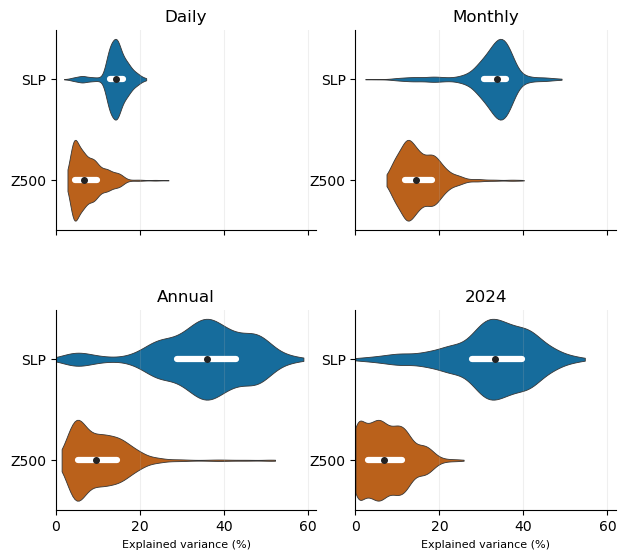

In [10]:
#{"box", "quart", "point", "stick", None}
groups = [
    ("Daily",   explained_var_msl,     explained_var_z500),
    ("Monthly", explained_var_msl_mon, explained_var_z500_mon),
    ("Annual",  explained_var_msl_ann, explained_var_z500_ann),
    ("2024",    explained_var_msl_2024, explained_var_z500_2024),
]

def vals(da):
    x = da.where((da.lat >= 22) & (da.lat <= 30) &
                 (da.lon >= 75) & (da.lon <= 85), drop=True)
    x = x.compute().values.ravel()
    return x[np.isfinite(x)] * 100

fig, axs = plt.subplots(2, 2, figsize=(7,6), sharex=True)
fig.subplots_adjust(left=.1, right=.9, bottom=.1, top=.9,wspace=.15, hspace=.40)

for ax, (title, msl, z500) in zip(axs.flat, groups):
    data=[vals(msl), vals(z500)]
    sns.violinplot(data=data, orient="h", inner=None,cut=0, palette=["#0072B2", "#D55E00"], linewidth=.6, ax=ax)
    for i, d in enumerate(data):
        q25, med, q75 = np.percentile(d, [25, 50, 75])
        ax.plot([q25, q75], [i, i], color="white", lw=4.5, solid_capstyle="round")
        ax.plot(med, i, "o", color="#222222", ms=4, zorder=5)
    ax.set(yticks=[0, 1], yticklabels=["SLP", "Z500"], title=title)
    ax.grid(axis="x", alpha=.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim([0,62])

for ax in axs[1]:
    ax.set_xlabel("Explained variance (%)",fontsize=8)


#fig.savefig('ExplainedVariance.pdf', dpi=300,  transparent=True)
plt.show()